# GRUMP ANALYSIS 

In [1]:
import pandas as pd
import copy
import numpy as np
import scipy as sp
import searoute as sr
from geopy.distance import geodesic
import matplotlib.pyplot as plt
from itertools import cycle

Plot style

In [2]:
plt.rcParams.update({
    "text.usetex": False, 
    "mathtext.fontset": "cm", 
    "font.family": "serif",
    "axes.formatter.use_mathtext": True,
    "font.size": 13,            
    "axes.labelsize": 16,       
    "axes.titlesize": 18,       
    "xtick.labelsize": 13,      
    "ytick.labelsize": 13,      
    "legend.fontsize": 12,      
    "axes.linewidth": 1.2       
})

In [3]:
# subset the data for each cruise
# the stations are selected so to obtain a homogeneous transect
# for the Taylor analysis, sort the samples by distance 
# (longitudinal/latitudinal)
def get_cruise_subset(data_GRUMP,cruise_id,type_id):

	if(cruise_id == "AU1603"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by="lon",inplace=True)
	elif(cruise_id == "CLIVAR IO9N"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise = data_cruise[data_cruise["lat"] > -20]
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "D357,JC068"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "IN2016_V03_NORTH"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id[0:10]])
		data_cruise = data_cruise[data_cruise["lat"] > -35]
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "IN2016_V03_SOUTH"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id[0:10]])
		data_cruise = data_cruise[data_cruise["lat"] < -35]
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "IND2017_V01"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "JC039"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "JC053"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "KM1906"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by=["lat", "lon", "Station"],inplace=True)
	elif(cruise_id == "MGL1704"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by=["lat", "lon", "Station"],inplace=True)
	elif(cruise_id == "PE319, PE321, JC057, PE358"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise = data_cruise[data_cruise["lat"] < 5]
		df_coord = data_cruise[["Station","lon","lat"]].drop_duplicates()
		rem_lon = df_coord[(df_coord["lon"] > -40) & (df_coord["lat"] < -40)]["lon"].values[0]
		rem_lat = df_coord[(df_coord["lon"] > -40) & (df_coord["lat"] < -40)]["lat"].values[0]
		data_cruise = data_cruise[(data_cruise["lon"] != rem_lon) | (data_cruise["lat"] != rem_lat)]
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "POTATOE"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise.sort_values(by="lat",inplace=True)
	elif(cruise_id == "SS2011, TAN1109"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise = data_cruise[data_cruise["lon"] < -120]
		data_cruise.sort_values(by="lon",inplace=True)
	elif(cruise_id == "ZHNG02RR"):
		data_cruise = copy.deepcopy(data_GRUMP[data_GRUMP["cruise"]==cruise_id])
		data_cruise = data_cruise[data_cruise["lat"] < -50]
		data_cruise.sort_values(by="lat",inplace=True)
	else:
		print("this cruise is not used in the spatial analysis")
		quit()

	if(type_id == "16S"):
		data_cruise = data_cruise[data_cruise["Sequence_Type"]=="Prokaryotic_16S"]
	elif(type_id == "18S"):
		data_cruise = data_cruise[data_cruise["Sequence_Type"]=="Eukaryote_18S"]
	else:
		print("wrong sequence type")
		quit()

	return(data_cruise)

# calculate the distances between consecutive stations in the cruise
def get_stepdistances_cruise(data_GRUMP,cruise_id,type_id):

	data_cruise = get_cruise_subset(data_GRUMP,cruise_id,type_id)

	df_stations = data_cruise[["Station","lon","lat"]].drop_duplicates()

	vec_distances = np.zeros(len(df_stations.index)-1)
	for i in range(len(df_stations.index)-1):
		vec_distances[i] = geodesic((float(df_stations["lat"].values[i]),float(df_stations["lon"].values[i])), 
						(float(df_stations["lat"].values[i+1]),float(df_stations["lon"].values[i+1]))).kilometers
			
	return(vec_distances)

# calculate the consecutive distances for each cruise
def get_stepdistances(data_GRUMP,vec_cruise):
	
	df_dist = None

	for i in range(len(vec_cruise)):

		df_cruise = pd.DataFrame({"distance":get_stepdistances_cruise(data_GRUMP,vec_cruise[i],"16S")})
		df_cruise["cruise"] = vec_cruise[i]
		if(i == 0):
			df_dist = df_cruise
		else:
			df_dist = pd.concat([df_dist,df_cruise])
	
	return(df_dist[["cruise","distance"]])

# calculate the distance between any pair of stations in a cruise
def get_distance(df_pair,cruise_id):

	# for these cruises, explicitly define in-water distances
	if(cruise_id in ["JC039","JC053","POTATOE","PE319, PE321, JC057, PE358"]):
		dist_ij = sr.searoute([df_pair["lon"].values[0],df_pair["lat"].values[0]],
						[df_pair["lon"].values[1],df_pair["lat"].values[1]],units="km").properties["length"]
		if(dist_ij == 0):
			return(geodesic((df_pair["lat"].values[0],df_pair["lon"].values[0]), 
						(df_pair["lat"].values[1],df_pair["lon"].values[1])).kilometers)

		return(dist_ij)
	# for all other cruises, just use geodesic distances (in the middle of the ocean)
	else:
		return(geodesic((df_pair["lat"].values[0],df_pair["lon"].values[0]), 
						(df_pair["lat"].values[1],df_pair["lon"].values[1])).kilometers)

# calculate the correlation lengths for a cruise and for a specific type (16S / 18S)
# calculation for the Pearson correlation, Jaccard correlation and normalised correlation
def get_correl_cruise(data_GRUMP,cruise_id,type_id):

	data_cruise = get_cruise_subset(data_GRUMP,cruise_id,type_id)
	df_stations = data_cruise[["Station","lon","lat"]].drop_duplicates()
	data_cruise = data_cruise.groupby(["Station","ASV_hash"]).agg({"Raw_Sequence_Counts":"sum"}).reset_index()
	data_cruise = data_cruise.pivot(index='ASV_hash', columns='Station', values='Raw_Sequence_Counts').fillna(0)

	vec_distances = np.zeros(int(len(df_stations.index)*(len(df_stations.index)-1)/2))
	vec_cor = np.zeros(int(len(df_stations.index)*(len(df_stations.index)-1)/2))
	vec_jac = np.zeros(int(len(df_stations.index)*(len(df_stations.index)-1)/2))
	vec_nor = np.zeros(int(len(df_stations.index)*(len(df_stations.index)-1)/2))

	# calculate pairwise correlations and distances
	k = 0
	for i in range(len(df_stations.index)-1):
		for j in range(i+1,len(df_stations.index)):
			vec_distances[k] = get_distance(df_stations.iloc[[i,j],:],cruise_id)
			ind_i = np.where(data_cruise.columns == df_stations["Station"].values[i])[0]
			ind_j = np.where(data_cruise.columns == df_stations["Station"].values[j])[0]

			vecA = data_cruise.iloc[:,ind_i].values.flatten()
			vecB = data_cruise.iloc[:,ind_j].values.flatten()

			vec_cor[k] = sp.stats.pearsonr(vecA,vecB)[0]
			vec_jac[k] = np.sum((vecA>0)*(vecB>0))/(np.sum(vecA>0)+np.sum(vecB>0)-np.sum((vecA>0)*(vecB>0)))
			vec_nor[k] = len(vecA)*np.sum(vecA*vecB)/np.sum(vecA)/np.sum(vecB)

			k += 1

	# linear regression to get the correlation length
	i_0 = np.where(vec_cor > 0)[0]
	slope_cor, intercept, r, p_cor, err = sp.stats.linregress(vec_distances[i_0], np.log(vec_cor[i_0]))
	i_0 = np.where(vec_jac > 0)[0]
	slope_jac, intercept, r, p_jac, err = sp.stats.linregress(vec_distances[i_0], np.log(vec_jac[i_0]))
	i_0 = np.where(vec_nor > 0)[0]
	slope_nor, intercept, r, p_nor, err = sp.stats.linregress(vec_distances[i_0], np.log(vec_nor[i_0]))
	df_points_cor = pd.DataFrame({'cruise': cruise_id,'type': type_id, 'distance': vec_distances[i_0], 'correlation': vec_nor[i_0]})

	return (-1/slope_cor,p_cor,-1/slope_jac,p_jac,-1/slope_nor,p_nor), df_points_cor

# get the correlation length for all cruises and for 16S and 18S
def get_correl(data_GRUMP,vec_cruise):

    vec_cor = np.zeros(len(vec_cruise)*2)
    vec_jac = np.zeros(len(vec_cruise)*2)
    vec_nor = np.zeros(len(vec_cruise)*2)

    vec_pcor = np.zeros(len(vec_cruise)*2)
    vec_pjac = np.zeros(len(vec_cruise)*2)
    vec_pnor = np.zeros(len(vec_cruise)*2)
    
    list_df_corre = []

    for i in range(len(vec_cruise)):
        print(vec_cruise[i])
        
        res_16, df_16 = get_correl_cruise(data_GRUMP, vec_cruise[i], "16S")
        vec_cor[i], vec_pcor[i], vec_jac[i], vec_pjac[i], vec_nor[i], vec_pnor[i] = res_16
        list_df_corre.append(df_16)
        
        res_18, df_18 = get_correl_cruise(data_GRUMP, vec_cruise[i], "18S")
        idx = i + len(vec_cruise)
        vec_cor[idx], vec_pcor[idx], vec_jac[idx], vec_pjac[idx], vec_nor[idx], vec_pnor[idx] = res_18
        list_df_corre.append(df_18)

    df_G = pd.DataFrame({"gamma_corr":vec_cor,"p_corr":vec_pcor,
                "gamma_jacc":vec_jac,"p_jacc":vec_pjac,
                "gamma_norm":vec_nor,"p_norm":vec_pnor,
                "cruise":np.concatenate([vec_cruise,vec_cruise]),
                "type":np.concatenate([np.repeat("16S",len(vec_cruise)),np.repeat("18S",len(vec_cruise))])})
    
    df_corre_all = pd.concat(list_df_corre, ignore_index=True)

    return df_G, df_corre_all


# calculate the variance-in-function-of-mean plot for the Taylor's law
# for a cruise and for a type (16S / 18S)
def get_Taylor_points(data_GRUMP,cruise_id,type_id):

	data_cruise = get_cruise_subset(data_GRUMP,cruise_id,type_id)
	df_stations = data_cruise[["Station","lon","lat"]].drop_duplicates()
	data_cruise = data_cruise.groupby(["Station","ASV_hash"]).agg({"Raw_Sequence_Counts":"sum"}).reset_index()
	data_cruise = data_cruise.pivot(index='ASV_hash', columns='Station', values='Raw_Sequence_Counts').fillna(0).reset_index()
	data_cruise = pd.melt(data_cruise,id_vars="ASV_hash").rename(columns={"value":"Raw_Sequence_Counts"})

	df_out = None

	for i in range(1,len(df_stations.index)+1):

		cutN = int(np.floor(len(df_stations.index)/i)*i)
		df_key = pd.DataFrame({"Station":df_stations["Station"].values[0:cutN],
								"group":np.repeat(range(1,(int(cutN/i)+1)),i)})
		
		df_sub = data_cruise.merge(df_key,on="Station",how="inner").groupby(["group","ASV_hash"]).agg({"Raw_Sequence_Counts":"sum"}).reset_index().groupby(["group"]).agg(mean=('Raw_Sequence_Counts', 'mean'),var=('Raw_Sequence_Counts', 'var')).reset_index(drop=True)
		df_sub["Nstat"] = i
		if(i==1):
			df_out = df_sub
		else:
			df_out = pd.concat([df_out,df_sub])
		
	return(df_out.reset_index(drop=True))

# get the Taylor-law exponent for all cruises
def get_Taylor(data_GRUMP,vec_cruise):

	df_Tay = None
	vec_slope = np.zeros(len(vec_cruise)*2)

	# 16S
	for i in range(len(vec_cruise)):

		# get the variance-in-function-of-mean scatter plot
		df_cruise = get_Taylor_points(data_GRUMP,vec_cruise[i],"16S")
		df_cruise["cruise"] = vec_cruise[i]
		df_cruise["type"] = "16S"
		df_Tay_sum = df_cruise.groupby(["Nstat"]).agg({"mean":"mean","var":"mean"})
		# linear regression to get the exponent
		slope, intercept, r, p, err = sp.stats.linregress(np.log10(df_Tay_sum["mean"].values),np.log10(df_Tay_sum["var"].values))
		if(i == 0):
			df_Tay = df_cruise
		else:
			df_Tay = pd.concat([df_Tay,df_cruise])

		vec_slope[i] = slope

	# 18S
	for i in range(len(vec_cruise)):

		df_cruise = get_Taylor_points(data_GRUMP,vec_cruise[i],"18S")
		df_cruise["cruise"] = vec_cruise[i]
		df_cruise["type"] = "18S"
		df_Tay_sum = df_cruise.groupby(["Nstat"]).agg({"mean":"mean","var":"mean"})
		slope, intercept, r, p, err = sp.stats.linregress(np.log10(df_Tay_sum["mean"].values),np.log10(df_Tay_sum["var"].values))
		df_Tay = pd.concat([df_Tay,df_cruise])

		vec_slope[i+len(vec_cruise)] = slope

	df_Tay_coef = pd.DataFrame({"coef_Tay":vec_slope,
						"cruise":np.concatenate([vec_cruise,vec_cruise]),
						"type":np.concatenate([np.repeat("16S",len(vec_cruise)),np.repeat("18S",len(vec_cruise))])})

	return((df_Tay,df_Tay_coef))

# theory
def psi(z):
	with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
		term = (1 - np.exp(-2 * z)) / (2 * z)
		result = 1 - term
	result = np.where(np.isfinite(result), result, np.nan)
	return result


def TL(x, G, v, scale):
	x = np.atleast_1d(x)
	z_x = x / (2 * G)
	num = x * v * psi(z_x)*2*G
	den = scale**2
	return num / den

# chisquares analysis
def loglik_TL(params, x, y, scale):
	G, v = params
	if G <= 0.1 or v <= 0: return 1e15
	y_pred = TL(x, G, v, scale)
	if np.any(y_pred <= 0): return 1e15
	return np.sum((np.log(y) - np.log(y_pred))**2)




Data

In [ ]:
data_GRUMP = pd.read_csv(r"GRUMP_DATASET.csv",
	usecols=["lat","lon","depth","Station","cruise","Sequence_Type",
				"Raw_Sequence_Counts","ASV_hash"])  # Download the file from Zenodo

# only select surface samples
data_GRUMP = data_GRUMP[data_GRUMP["depth"] < 20 ]

# list of cruises used in the spatial analysis
vec_cruise = np.array(["AU1603","CLIVAR IO9N","D357,JC068",
		"IN2016_V03_NORTH","IN2016_V03_SOUTH","IND2017_V01",
		"JC039","JC053","KM1906","MGL1704",
		"PE319, PE321, JC057, PE358","POTATOE","SS2011, TAN1109",
		"ZHNG02RR"])

# calculate the in-water distances between pairs of stations 
df_dist = get_stepdistances(data_GRUMP,vec_cruise)

# calculate the correlation lengths
df_G, df_corre = get_correl(data_GRUMP, vec_cruise)

# calculate the Taylor's law
df_var,df_cmp = get_Taylor(data_GRUMP,vec_cruise)

AU1603
CLIVAR IO9N
D357,JC068
IN2016_V03_NORTH
IN2016_V03_SOUTH
IND2017_V01
JC039
JC053
KM1906
MGL1704
PE319, PE321, JC057, PE358
POTATOE
SS2011, TAN1109
ZHNG02RR


In [5]:
var_col = 'var'
nstat_col = 'Nstat'
boat_col = 'cruise'
type_col = 'type'
dist_boat_col = 'cruise'
dist_val_col = 'distance'


df_G['boat'] = df_G['cruise'].astype(str).str.strip()
G_col = 'gamma_norm'

df_var[boat_col] = df_var[boat_col].astype(str).str.strip()
df_dist[dist_boat_col] = df_dist[dist_boat_col].astype(str).str.strip()
df_cmp['cruise'] = df_cmp['cruise'].astype(str).str.strip()

full_set = df_var[boat_col].unique()
boat_prefixes = ("PE319", "PE321", "JC057", "PE358")

boats = [
    b for b in full_set
    if not str(b).startswith(boat_prefixes) and str(b) != "IN2016_V03"
]

exponents_theory = []
exponents_data = []
boat_labels_alpha = []

target_type = "16S"

for boat in boats:
    dist_subset = df_dist[df_dist[dist_boat_col] == boat][dist_val_col].to_numpy()
    if len(dist_subset) == 0: continue
    scale = np.median(dist_subset)
    
    subset = df_var[(df_var[boat_col] == boat) & (df_var[type_col] == target_type)]
    if subset.empty: continue
    
    grouped = subset.groupby(nstat_col)[var_col].mean().reset_index()
    N = grouped[nstat_col].astype(float).to_numpy()
    mean_var = grouped[var_col].to_numpy()
    
    G_row = df_G[(df_G['boat'] == boat) & (df_G['type'] == target_type)]
    if G_row.empty: continue
    try:
        G = float(G_row.iloc[0][G_col])
    except: continue

    if 1 in grouped[nstat_col].values:
        v = grouped[grouped[nstat_col] == 1][var_col].values[0]
    else: continue

    x = N * scale
    TL_vals = TL(x, G, v, scale)

    mask = TL_vals > 0
    if np.sum(mask) < 2: continue
    logx = np.log10(x[mask])
    logTL = np.log10(TL_vals[mask])
    slope_theory, _ = np.polyfit(logx, logTL, 1)
    
    cmp_row = df_cmp[(df_cmp['cruise'] == boat) & (df_cmp['type'] == target_type)]
    if not cmp_row.empty:
        exponents_data.append(cmp_row['coef_Tay'].values[0])
        exponents_theory.append(slope_theory)
        boat_labels_alpha.append(boat)

exponents_theory = np.array(exponents_theory)
exponents_data = np.array(exponents_data)

print(f"Results for {target_type}:")
for b, th, emp in zip(boat_labels_alpha, exponents_theory, exponents_data):
    print(f"{b}: Theoretical = {th:.3f} | Empirical = {emp:.3f}")

Results for 16S:
AU1603: Theoretical = 1.604 | Empirical = 1.606
CLIVAR IO9N: Theoretical = 1.940 | Empirical = 1.996
D357,JC068: Theoretical = 1.943 | Empirical = 1.877
IN2016_V03_NORTH: Theoretical = 1.789 | Empirical = 1.659
IN2016_V03_SOUTH: Theoretical = 1.680 | Empirical = 1.716
IND2017_V01: Theoretical = 1.829 | Empirical = 1.872
JC039: Theoretical = 1.838 | Empirical = 1.516
JC053: Theoretical = 1.930 | Empirical = 1.874
KM1906: Theoretical = 1.784 | Empirical = 1.759
MGL1704: Theoretical = 1.738 | Empirical = 1.630
POTATOE: Theoretical = 1.701 | Empirical = 1.665
SS2011, TAN1109: Theoretical = 1.986 | Empirical = 1.956
ZHNG02RR: Theoretical = 1.612 | Empirical = 1.691


Plot Spatial Taylor's Law

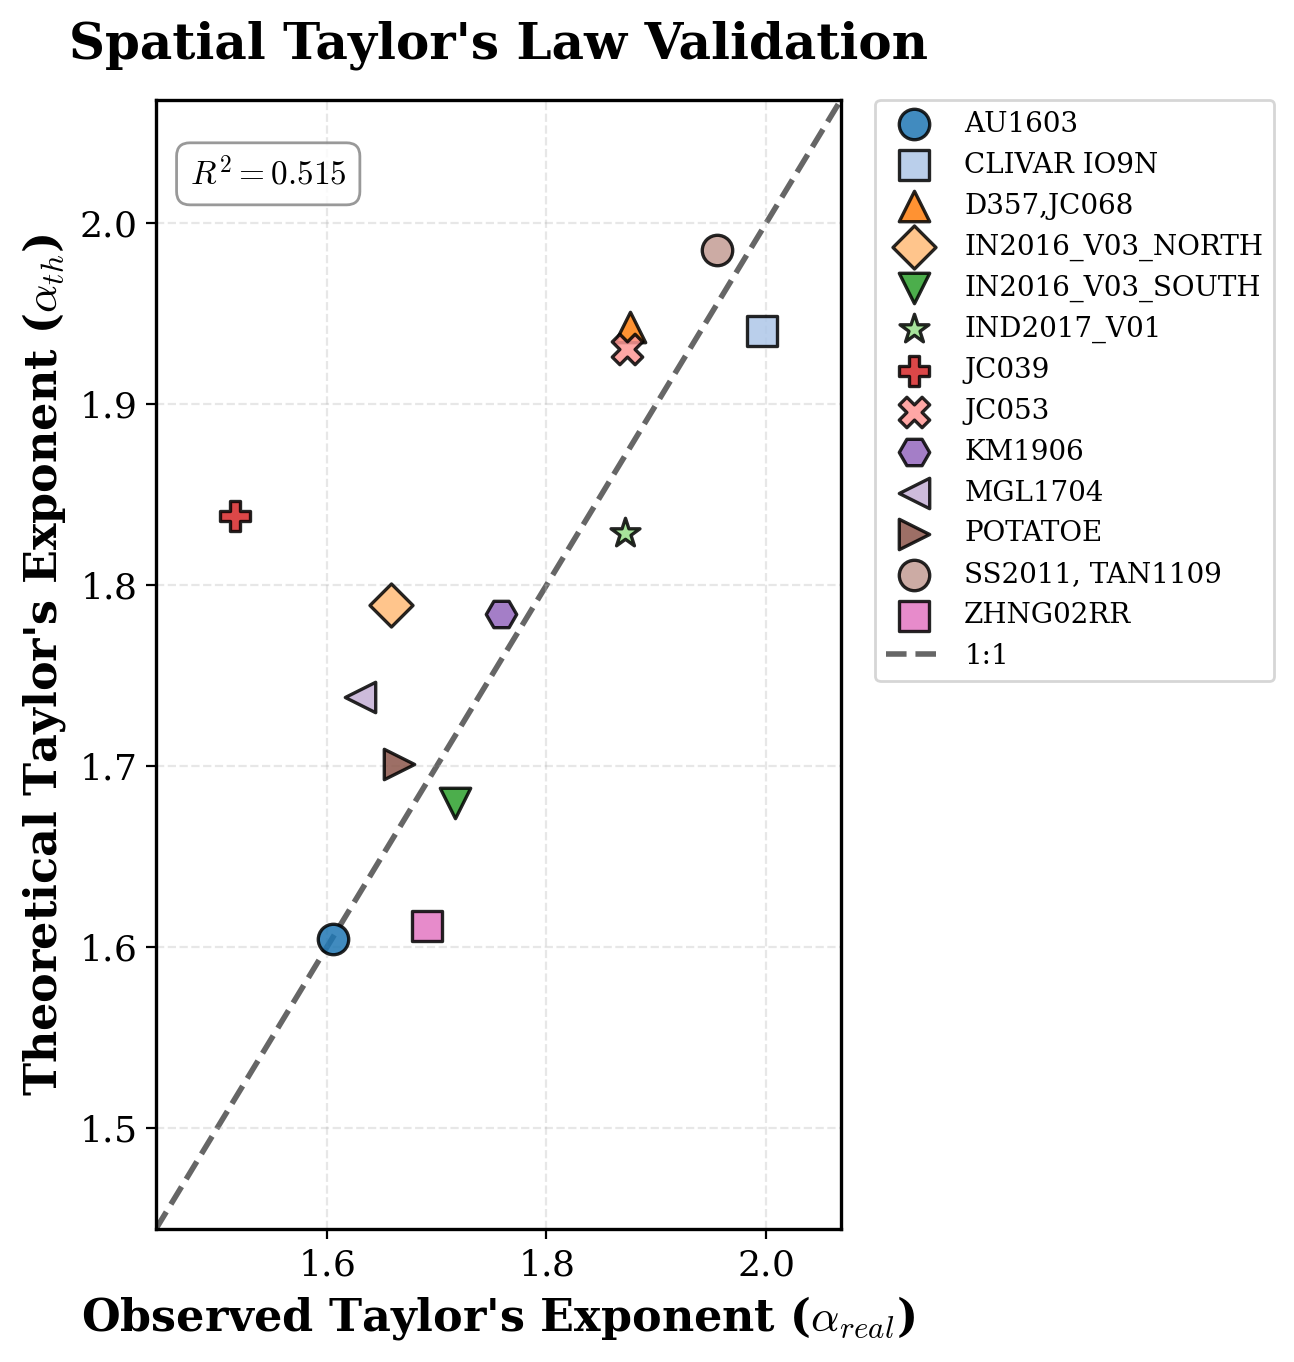

In [ ]:
from itertools import cycle
from scipy.stats import linregress 

fig, ax = plt.subplots(figsize=(8, 7), dpi=200)
cmap = plt.colormaps['tab20']
markers = cycle(['o', 's', '^', 'D', 'v', '*', 'P', 'X', 'H', '<', '>'])

for i, boat in enumerate(boat_labels_alpha):
    marker = next(markers)
    ax.scatter(exponents_data[i], exponents_theory[i], 
               s=120, color=cmap(i % 20), marker=marker, label=boat, 
               edgecolor='black', lw=1.2, alpha=0.85, zorder=3)

x = np.array(exponents_data, dtype=float)
y = np.array(exponents_theory, dtype=float)

mask = ~np.isnan(x) & ~np.isnan(y)
x_clean = x[mask]
y_clean = y[mask]

slope, intercept, r_value, p_value, std_err = linregress(x_clean, y_clean)
r_squared = r_value**2

bbox_props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(0.05, 0.95, f'$R^2 = {r_squared:.3f}$', transform=ax.transAxes, 
        fontsize=12, fontweight='bold', verticalalignment='top', 
        bbox=bbox_props, zorder=5)

# ax.plot(x_clean, intercept + slope * x_clean, color='red', ls='-', lw=1.5, zorder=2, label="Linear Fit")

# Axes
min_val = min(np.nanmin(exponents_data), np.nanmin(exponents_theory))
max_val = max(np.nanmax(exponents_data), np.nanmax(exponents_theory))
margin = (max_val - min_val) * 0.15
lims = [min_val - margin, max_val + margin]

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.grid(True, which='major', linestyle='--', alpha=0.3, zorder=0)
ax.plot(lims, lims, color='black', ls='--', lw=2, alpha=0.6, zorder=1, label="1:1")

ax.set_xlabel(r"Observed Taylor's Exponent ($\alpha_{real}$)", fontweight='bold')
ax.set_ylabel(r"Theoretical Taylor's Exponent ($\alpha_{th}$)", fontweight='bold')
ax.set_title("Spatial Taylor's Law", fontweight='bold', pad=15)

ax.legend(frameon=True, fontsize=10, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

fig.tight_layout(rect=[0, 0, 0.85, 1])
# plt.show()
#fig.savefig("exponent.pdf", format="pdf")

Plot Gamma

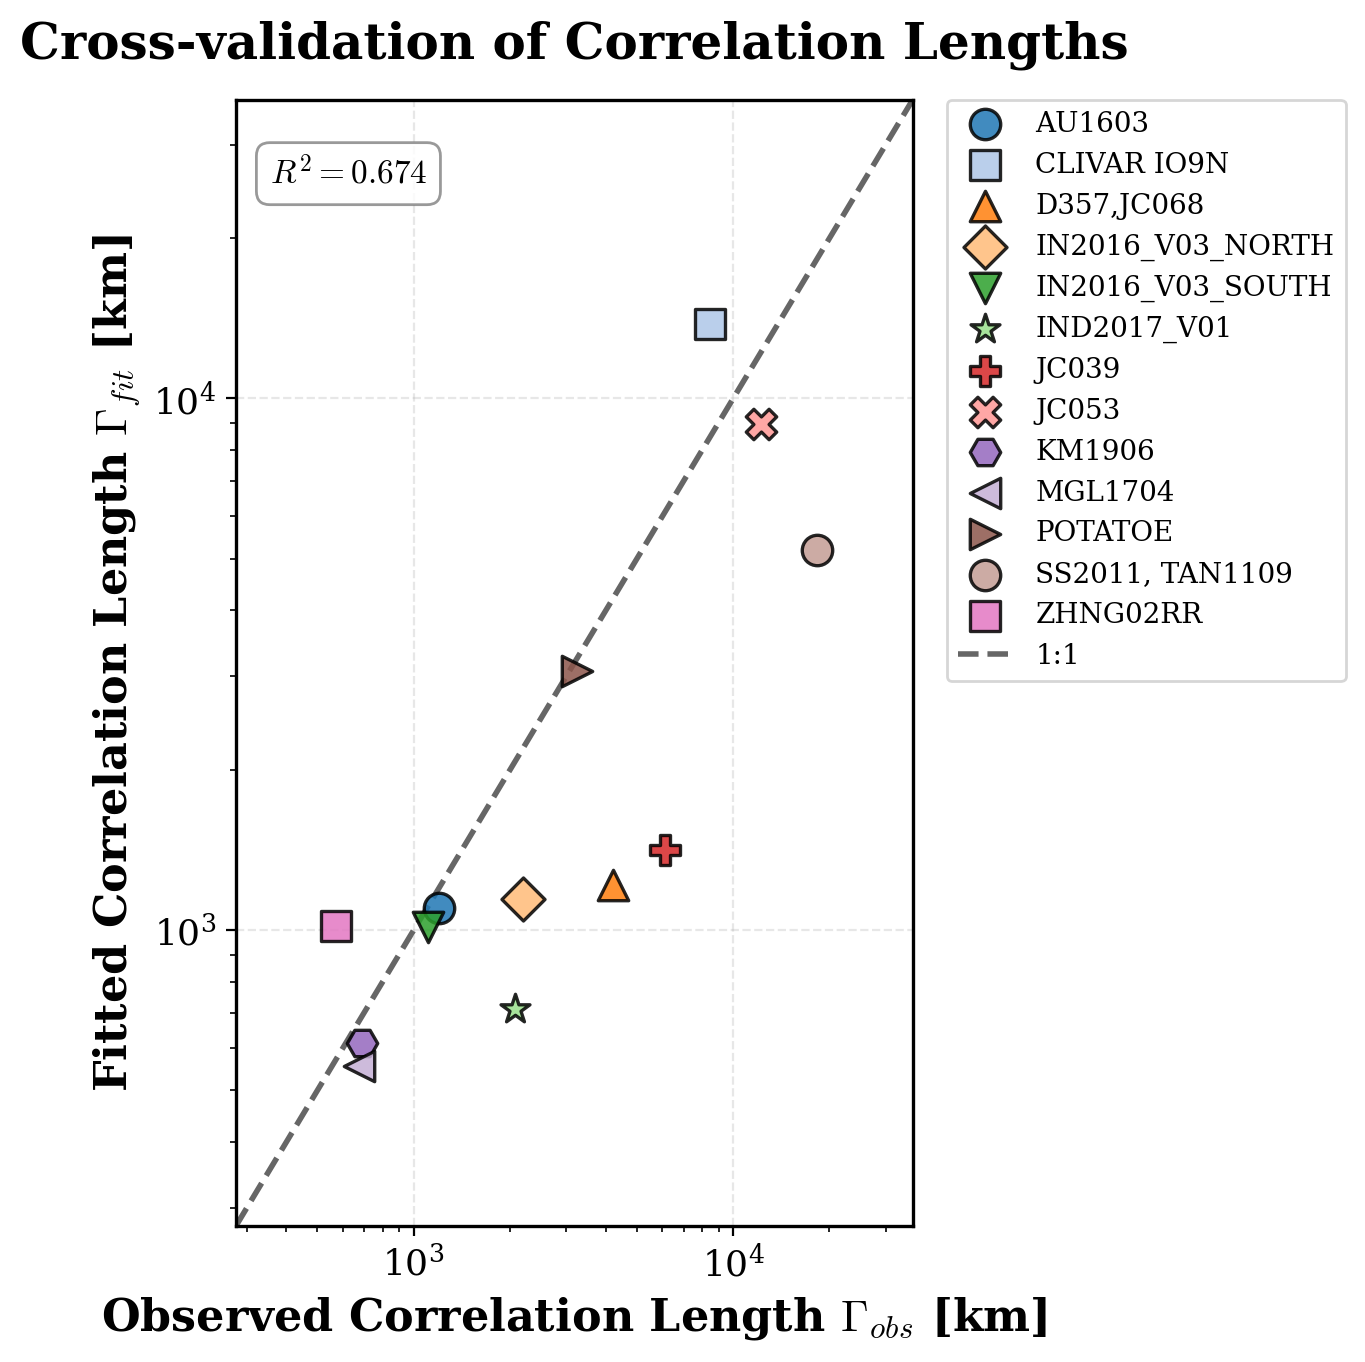

In [ ]:
results_gamma = []

for boat in boats:
    
    dist_subset = df_dist[df_dist[dist_boat_col] == boat][dist_val_col].to_numpy()
    if len(dist_subset) == 0: continue
    scale_val = np.mean(dist_subset)


    subset = df_var[df_var[boat_col] == boat]
    if subset.empty: continue
    grouped = subset.groupby(nstat_col)[var_col].mean().reset_index()
    
    x_data = grouped[nstat_col].astype(float).to_numpy() * scale_val
    y_data = grouped[var_col].to_numpy()

    g_obs_row = df_G[df_G['boat'] == boat]
    if g_obs_row.empty: continue
    G_observed = float(g_obs_row.iloc[0][G_col])

    try:
        res = sp.optimize.minimize(loglik_TL, x0=[G_observed, y_data[0]], 
                       args=(x_data, y_data, scale_val),
                       method='Nelder-Mead', bounds=[(100, 100000), (1e-3, None)])

        if res.success:
            results_gamma.append({'boat': boat, 'G_obs': G_observed, 'G_fit': res.x[0]})
    except:
        continue

df_final_gamma = pd.DataFrame(results_gamma)

# R^2 on log-log scale
log_x = np.log10(df_final_gamma['G_obs'].values)
log_y = np.log10(df_final_gamma['G_fit'].values)

slope, intercept, r_value, p_value, std_err = linregress(log_x, log_y)
r_squared_log = r_value**2


fig, ax = plt.subplots(figsize=(8, 7), dpi=200)
cmap = plt.colormaps['tab20']
markers = cycle(['o', 's', '^', 'D', 'v', '*', 'P', 'X', 'H', '<', '>'])

for i, row in df_final_gamma.iterrows():
    marker = next(markers)
    ax.scatter(row['G_obs'], row['G_fit'], 
               s=120, color=cmap(i % 20), marker=marker, label=row['boat'], 
               edgecolor='black', lw=1.2, alpha=0.85, zorder=3)

min_val_g = min(df_final_gamma['G_obs'].min(), df_final_gamma['G_fit'].min())
max_val_g = max(df_final_gamma['G_obs'].max(), df_final_gamma['G_fit'].max())
lim_min = min_val_g * 0.5
lim_max = max_val_g * 2.0

ax.set_xlim(lim_min, lim_max)
ax.set_ylim(lim_min, lim_max)
ax.set_xscale('log')
ax.set_yscale('log')
ax.grid(True, which='major', linestyle='--', alpha=0.3, zorder=0)

ax.plot([lim_min, lim_max], [lim_min, lim_max], color='black', ls='--', lw=2, alpha=0.6, zorder=1, label="1:1")

bbox_props = dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(0.05, 0.95, f'$R^2 = {r_squared_log:.3f}$', transform=ax.transAxes, 
        fontsize=12, fontweight='bold', verticalalignment='top', 
        bbox=bbox_props, zorder=5)

ax.set_xlabel(r"Observed Correlation Length $\Gamma_{obs}$ [km]", fontweight='bold')
ax.set_ylabel(r"Fitted Correlation Length $\Gamma_{fit}$ [km]", fontweight='bold')
ax.set_title("Cross-validation of Correlation Lengths", fontweight='bold', pad=15)
ax.legend(frameon=True, fontsize=10, bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)

fig.tight_layout(rect=[0, 0, 0.85, 1])

#fig.savefig("exponent_gamma.pdf", format="pdf")

691.5146468043287 192854.12393721577 59.86784511744581


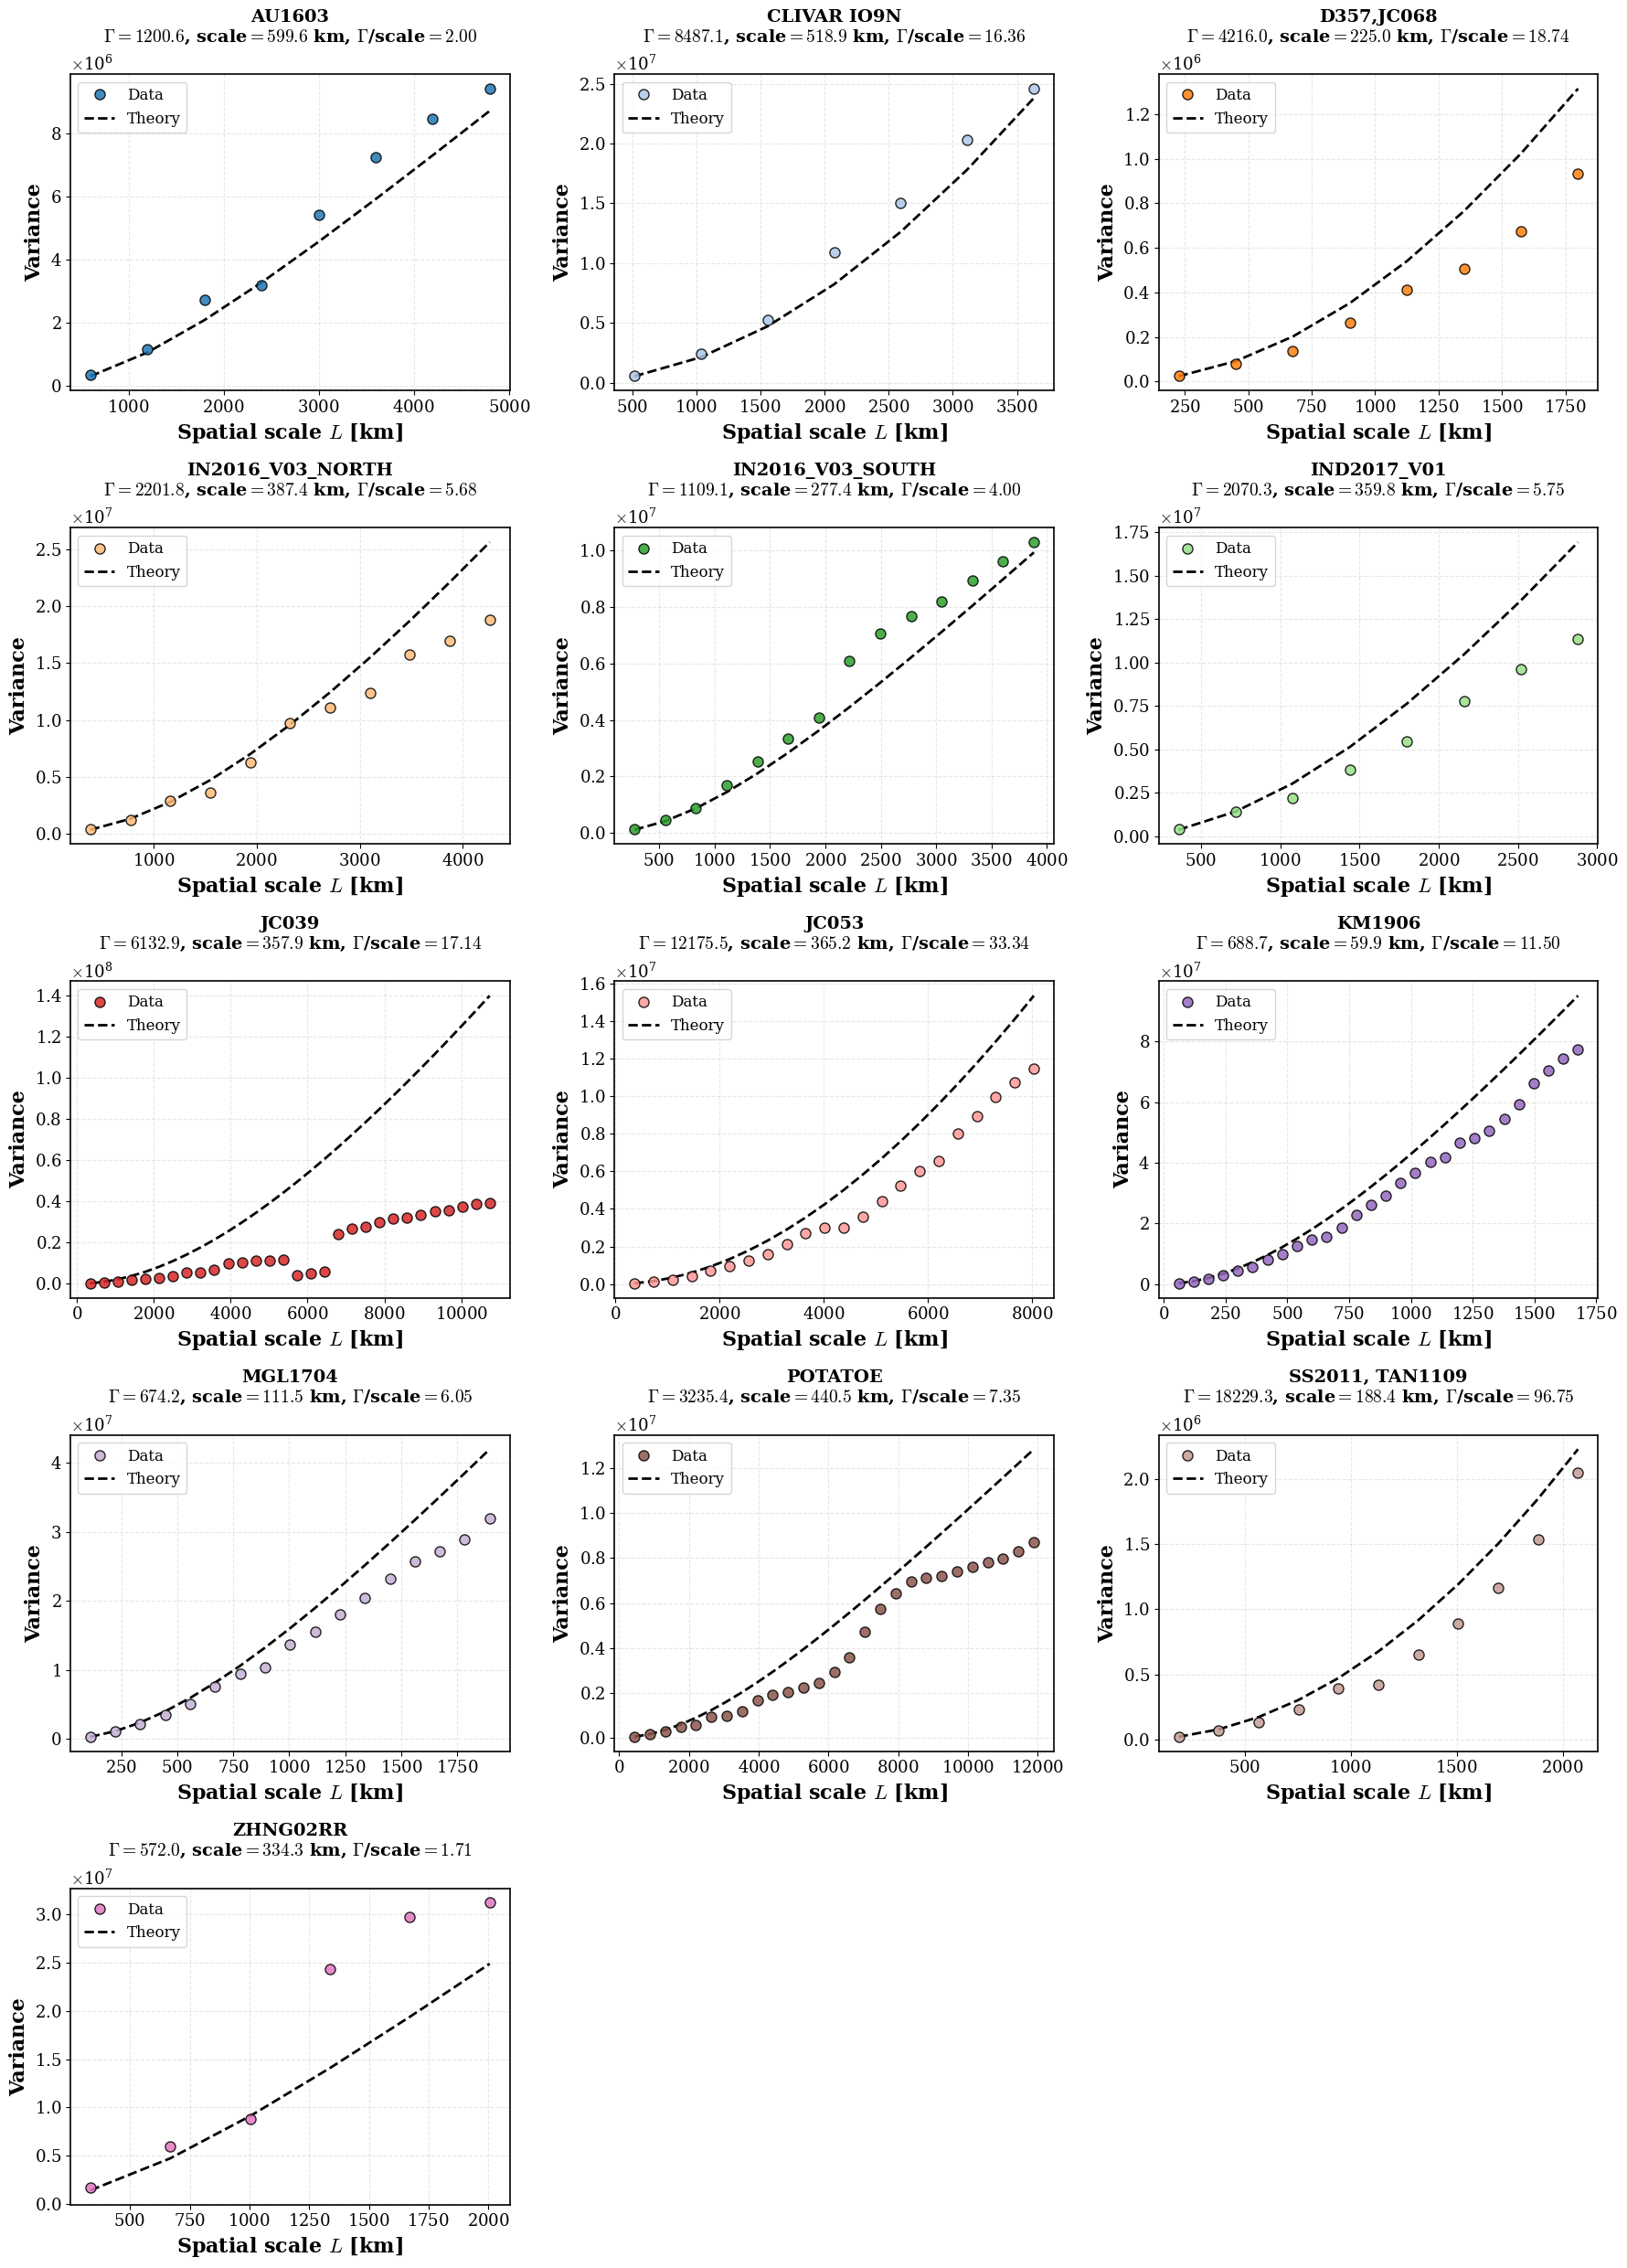

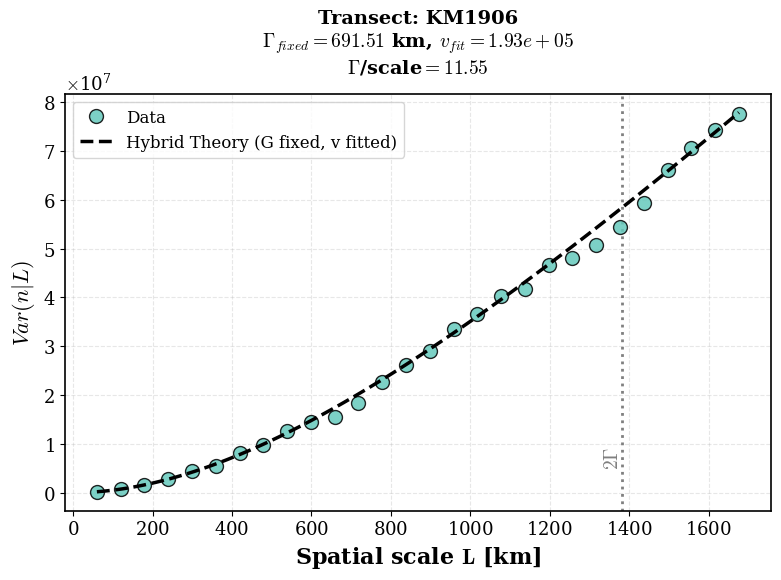

In [ ]:
nboats = len(boats)
ncols = 3  
nrows = int(np.ceil(nboats / ncols))


fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), facecolor='white')
axes = axes.flatten()

cmap = plt.colormaps['tab20']

last_idx = 0

for i, boat in enumerate(boats):
	ax = axes[i]
	color = cmap(i % 20)
	last_idx = i

	# data
	dist_subset = df_dist[df_dist[dist_boat_col] == boat][dist_val_col].to_numpy()
	if len(dist_subset) == 0: continue
	scale = np.median(dist_subset)  # median

	subset = df_var[df_var[boat_col] == boat]
	if subset.empty: continue
	grouped = subset.groupby(nstat_col)[var_col].mean().reset_index()

	N = grouped[nstat_col].astype(float).to_numpy()
	mean_var = grouped[var_col].to_numpy()

   
	G_row = df_G[df_G['boat'] == boat]
	if G_row.empty: continue
	G = float(G_row.iloc[0][G_col])

	if 1 in grouped[nstat_col].values:
		v = float(grouped[grouped[nstat_col] == 1][var_col].values[0])
	else: continue


	x = N * scale
	TL_vals = TL(x, G, v, scale)

	# plots
	ax.plot(x, mean_var, "o", color=color, markersize=8, markeredgecolor='black', label="Data", alpha=0.85, zorder=3)
	# theory
	ax.plot(x, TL_vals, "--", color='black', linewidth=2, label="Theory", zorder=2)

	# Ratio Gamma/scale
	r = G / scale


	ax.set_xlabel("Spatial scale $L$ [km]", fontweight='bold')
	ax.set_ylabel("Variance", fontweight='bold')
	ax.set_xscale("log")
	ax.set_yscale("log")

	ax.set_title(f"{boat}\n$\\Gamma={G:.1f}$, scale$={scale:.1f}$ km, $\\Gamma$/scale$={r:.2f}$", 
                 fontsize=14, fontweight='bold', pad=10)
    

    
	ax.grid(True, which="both", linestyle="--", alpha=0.3, zorder=0)
	ax.legend(frameon=True, loc='upper left')


for j in range(last_idx + 1, len(axes)):
	fig.delaxes(axes[j])

fig.tight_layout()
#fig.savefig("expon_fits.pdf",format="pdf")

def loglik_v_only(v_param, G_fixed, x, y, scale):
    v = v_param[0]
    if v <= 0: 
        return 1e15 
    y_pred = TL(x, G_fixed, v, scale)
    return np.sum((np.log(y) - np.log(y_pred))**2)

target_boat = "KM1906"

dist_subset = df_dist[df_dist.iloc[:, 0].astype(str).str.strip() == target_boat].iloc[:, 1].to_numpy()
scale_val = np.median(dist_subset)

G_fixed = float(df_G[df_G.iloc[:, 6].astype(str).str.strip() == target_boat].iloc[0, 2])

boat_col_var = df_var.columns[3]
subset = df_var[df_var[boat_col_var].astype(str).str.strip() == target_boat]
grouped = subset.groupby(df_var.columns[2])[df_var.columns[1]].mean().reset_index()

N_vals = grouped.iloc[:, 0].astype(float).to_numpy()
x_data = N_vals * scale_val
y_data = grouped.iloc[:, 1].to_numpy()

z_guess = x_data[0] / (2 * G_fixed)
psi_guess = np.maximum(psi(z_guess), 1e-8)
v_guess = (y_data[0] * scale_val) / (2 * G_fixed * x_data[0] * psi_guess)

res_v = sp.optimize.minimize(loglik_v_only, x0=[v_guess], args=(G_fixed, x_data, y_data, scale_val), method='Nelder-Mead')
v_mle = res_v.x[0] 

fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')

x_curve = np.linspace(min(x_data), max(x_data), 100)
y_curve = TL(x_curve, G_fixed, v_mle, scale_val)

print(G_fixed, v_mle, scale_val)

ax.plot(x_data, y_data, "o", color="#65C9BC", markersize=10, markeredgecolor='black', label="Data", alpha=0.85, zorder=3)
ax.plot(x_curve, y_curve, "--", color='black', linewidth=2.5, label="Hybrid Theory (G fixed, v fitted)", zorder=4)

ax.axvline(2 * G_fixed, color='gray', linestyle=':', lw=2, zorder=2)
ax.text(2 * G_fixed, ax.get_ylim()[0] + (ax.get_ylim()[1]-ax.get_ylim()[0])*0.1, r'$2\mathbf{\Gamma}$', 
        color='gray', fontsize=14, fontweight='bold', rotation=90, va='bottom', ha='right')

ax.set_xlabel("Spatial scale $\mathbf{L}$ [km]", fontweight='bold')
ax.set_ylabel("$Var(n|L)$", fontweight='bold')

ratio = G_fixed / scale_val
ax.set_title(f"Transect: {target_boat}\n$\\Gamma_{{fixed}}={G_fixed:.2f}$ km, $v_{{fit}}={v_mle:.2e}$\n$\\Gamma$/scale$={ratio:.2f}$", 
             fontsize=14, fontweight='bold', pad=15)

ax.grid(True, which="both", linestyle="--", alpha=0.3, zorder=0)
ax.legend(frameon=True, loc='upper left')

plt.tight_layout()
#fig.savefig("expon_example.pdf",format="pdf")

Example of spatial correlation

In [10]:
df_corre.head()

,cruise,type,distance,correlation
0,AU1603,16S,174.585535,57.022039
1,AU1603,16S,717.806235,35.139812
2,AU1603,16S,1538.075788,24.886484
3,AU1603,16S,2165.702847,24.884449
4,AU1603,16S,2697.964447,21.132152


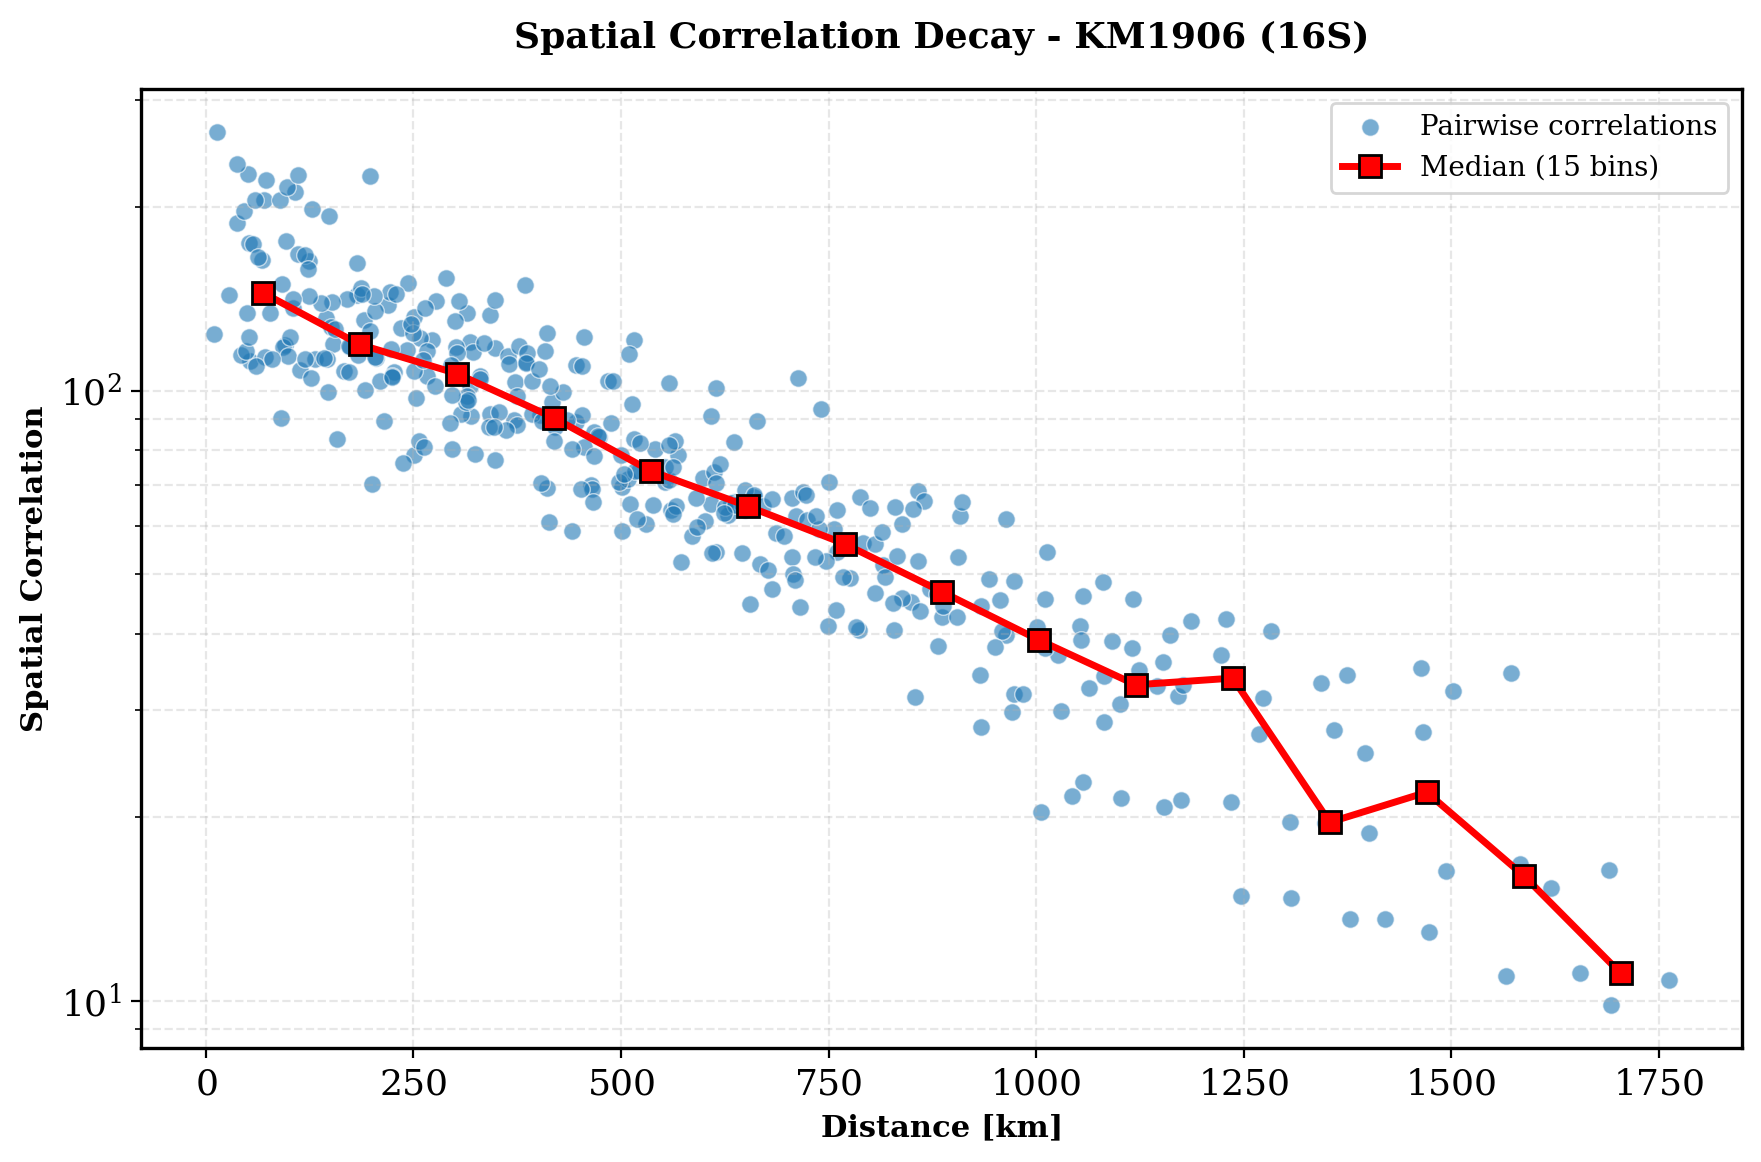

In [13]:
target_type = "16S"

df_plot = df_corre[(df_corre['cruise'] == target_boat) & (df_corre['type'] == target_type)].copy()

fig, ax = plt.subplots(figsize=(9, 6), dpi=200)

ax.scatter(df_plot['distance'], df_plot['correlation'], 
               alpha=0.6, s=40, color='#1f77b4', edgecolors='white', lw=0.5, 
               zorder=1, label='Pairwise correlations')

num_bins = 15
bins = np.linspace(df_plot['distance'].min(), df_plot['distance'].max(), num_bins + 1)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

df_plot['bin_idx'] = np.digitize(df_plot['distance'], bins) - 1

valid_centers = []
medians = []

for i in range(num_bins):
    bin_data = df_plot[df_plot['bin_idx'] == i]
    if not bin_data.empty:
        valid_centers.append(bin_centers[i])
        medians.append(bin_data['correlation'].median())

ax.plot(valid_centers, medians, marker='s', color='red', lw=2.5, markersize=8, 
        markeredgecolor='black', zorder=3, label=f'Median ({num_bins} bins)')

ax.set_yscale('log')

ax.grid(True, which='both', linestyle='--', alpha=0.3, zorder=0)
ax.set_xlabel('Distance [km]', fontweight='bold', fontsize=11)
ax.set_ylabel('Spatial Correlation', fontweight='bold', fontsize=11)
ax.set_title(f'Spatial Correlation Decay - {target_boat} ({target_type})', 
                fontweight='bold', fontsize=13, pad=15)
    
ax.legend(frameon=True, fontsize=10)

fig.tight_layout()    
  